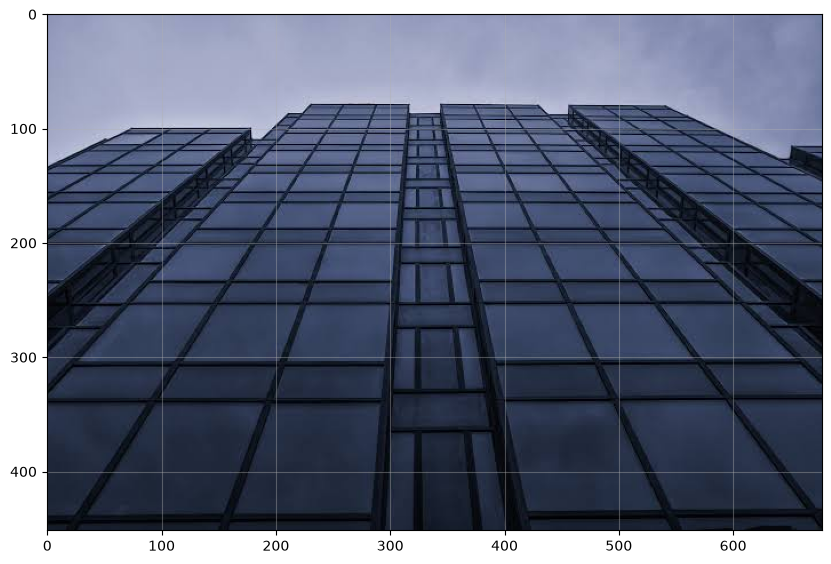

In [2]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt
bg   = cv.imread('../images/new_background.jpg')
flag = cv.imread('../images/flag.png')
plt.figure(figsize=(10, 8)); plt.imshow(cv.cvtColor(bg, cv.COLOR_BGR2RGB)); plt.grid(True, alpha=0.4); plt.show()

In [3]:
dst = np.float32([[x1,y1],[x2,y2],[x3,y3],[x4,y4]])     # top-left, top-right, bottom-right, bottom-left
h, w = flag.shape[:2]
src = np.float32([[0,0],[w,0],[w,h],[0,h]])

H = cv.getPerspectiveTransform(src, dst)
print("H =\n", np.round(H, 4))
warped = cv.warpPerspective(flag, H, (bg.shape[1], bg.shape[0]))
mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, (bg.shape[1], bg.shape[0])) > 0
blend = bg.copy()
blend[mask] = (0.35*bg[mask] + 0.65*warped[mask]).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, im_, t in zip(ax, [bg, flag, blend], ['Background', 'Flag', 'Result']):
    a.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB)); a.set_title(t); a.axis('off')
plt.show()

NameError: name 'x1' is not defined